<a href="https://colab.research.google.com/github/Mich-088/MAT422/blob/main/HW_3_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Homework 3.4

**Logistic Regression**



In [9]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

np.set_printoptions(precision=4, suppress=True)

**SIGMOID/LOGISTIC FUNCTION**

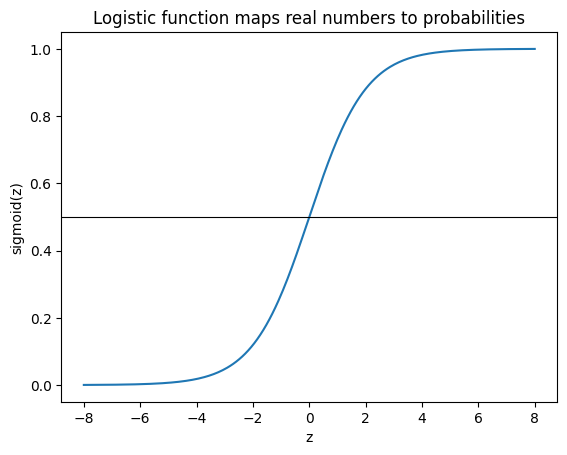

In [10]:

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

z = np.linspace(-8, 8, 300)
plt.plot(z, sigmoid(z))
plt.axhline(0.5, color="black", linewidth=0.8)
plt.xlabel("z")
plt.ylabel("sigmoid(z)")
plt.title("Logistic function maps real numbers to probabilities")
plt.show()

**BINARY CLASSIFICATION PROBABILITIES**

In [11]:
X, y = make_classification(n_samples=120, n_features=2, n_redundant=0, n_informative=2,
                           n_clusters_per_class=1, class_sep=1.2, random_state=422)
model = LogisticRegression()
model.fit(X, y)
pred = model.predict(X)
proba = model.predict_proba(X)[:, 1]

print("Coefficients:", model.coef_)
print("Intercept:", model.intercept_)
print("Training accuracy:", accuracy_score(y, pred))
print("Confusion matrix:")
print(confusion_matrix(y, pred))

Coefficients: [[0.9652 3.4485]]
Intercept: [2.6793]
Training accuracy: 0.975
Confusion matrix:
[[60  0]
 [ 3 57]]


**LOGOSTIC REGRESSION FITTING AND INTERPRETATION**

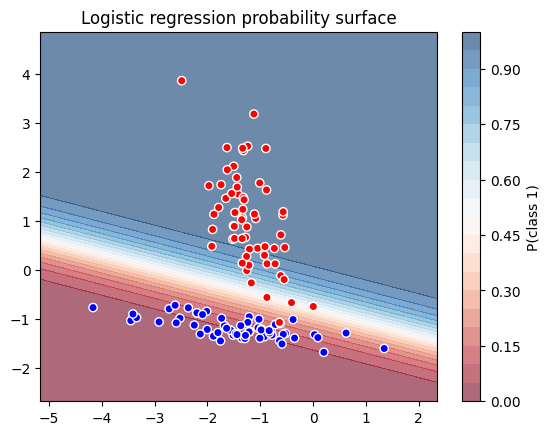

In [12]:

xx, yy = np.meshgrid(np.linspace(X[:,0].min()-1, X[:,0].max()+1, 150),
                     np.linspace(X[:,1].min()-1, X[:,1].max()+1, 150))
grid = np.c_[xx.ravel(), yy.ravel()]
zz = model.predict_proba(grid)[:, 1].reshape(xx.shape)

plt.contourf(xx, yy, zz, levels=20, cmap="RdBu", alpha=0.6)
plt.colorbar(label="P(class 1)")
plt.scatter(X[:,0], X[:,1], c=y, edgecolor="white", cmap="bwr")
plt.title("Logistic regression probability surface")
plt.show()
